# GDELT GKG — Preliminary Validation and EDA

## 0. Setup

In [ ]:
!pip -q install duckdb pyarrow

from pathlib import Path
import glob
import os
import shutil

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from IPython.display import display
from google.colab import drive

SEED = 42
MEMORY_LIMIT = '3GB'
THREADS = 2

plt.rcParams.update({
    'figure.dpi': 115,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
})

def human_number(x, pos=None):
    if abs(x) >= 1_000_000:
        return f'{x / 1_000_000:.1f}M'
    if abs(x) >= 1_000:
        return f'{x / 1_000:.0f}K'
    return f'{x:.0f}'

HUMAN = mtick.FuncFormatter(human_number)

drive.mount('/content/drive')

ROOT_CANDIDATES = [
    Path('/content/drive/MyDrive/Data-GDELT'),
    Path('/content/drive/MyDrive/Data - GDELT'),
]
DATA_ROOT = next((p for p in ROOT_CANDIDATES if p.exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Could not find Data-GDELT in MyDrive. Update ROOT_CANDIDATES.')

TMP_DIR = Path('/content/duckdb_tmp')
TMP_DIR.mkdir(exist_ok=True)

con = duckdb.connect()
con.execute(f"SET memory_limit='{MEMORY_LIMIT}'")
con.execute(f"SET threads={THREADS}")
con.execute(f"SET temp_directory='{TMP_DIR}'")
con.execute("SET preserve_insertion_order=false")

print('Drive root:', DATA_ROOT)
print('DuckDB memory limit:', MEMORY_LIMIT)
print('Local free disk:', f"{shutil.disk_usage('/content').free / 1e9:.1f} GB")

Mounted at /content/drive
Drive root: /content/drive/MyDrive/Data-GDELT
DuckDB memory limit: 3GB
Local free disk: 93.6 GB


In [ ]:
def q(name):
    return '"' + name.replace('"', '""') + '"'


def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"


def raw_profile(columns):
    expressions = []
    for c in columns:
        col = q(c)
        expressions.extend([
            f"SUM(CASE WHEN {col} IS NULL THEN 1 ELSE 0 END) AS {q(c + '__null')}",
            f"SUM(CASE WHEN {col} IS NOT NULL AND TRIM({col}) = '' THEN 1 ELSE 0 END) AS {q(c + '__empty')}",
            f"APPROX_COUNT_DISTINCT(NULLIF(TRIM({col}), '')) AS {q(c + '__unique')}",
        ])

    row = con.execute(
        'SELECT COUNT(*) AS rows, ' + ', '.join(expressions) + ' FROM raw'
    ).fetchdf().iloc[0]

    total = int(row['rows'])
    records = []
    for c in columns:
        nulls = int(row[f'{c}__null'])
        empty = int(row[f'{c}__empty'])
        records.append({
            'column': c,
            'null_count': nulls,
            'empty_count': empty,
            'missing_or_empty_pct': 100 * (nulls + empty) / total if total else 0,
            'approx_unique': int(row[f'{c}__unique']),
        })

    return total, pd.DataFrame(records)


def plot_missing_profile(profile, title):
    p = profile.sort_values('missing_or_empty_pct')
    fig, ax = plt.subplots(figsize=(9, max(3.6, 0.34 * len(p))))
    ax.barh(p['column'], p['missing_or_empty_pct'])
    ax.set_xlabel('Null or empty fields (%)')
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()


def numeric_validation(specs):
    expressions = []
    for c, spec in specs.items():
        dtype = spec['dtype']
        low = spec.get('low')
        high = spec.get('high')
        col = q(c)
        parsed = f"TRY_CAST(NULLIF(TRIM({col}), '') AS {dtype})"
        nonempty = f"{col} IS NOT NULL AND TRIM({col}) <> ''"

        expressions.extend([
            f"SUM(CASE WHEN {nonempty} AND {parsed} IS NULL THEN 1 ELSE 0 END) AS {q(c + '__parse_fail')}",
            f"SUM(CASE WHEN {parsed} = 0 THEN 1 ELSE 0 END) AS {q(c + '__zero')}",
            f"MIN({parsed}) AS {q(c + '__min')}",
            f"MAX({parsed}) AS {q(c + '__max')}",
        ])

        if low is not None and high is not None:
            expressions.append(
                f"SUM(CASE WHEN {parsed} IS NOT NULL AND ({parsed} < {low} OR {parsed} > {high}) THEN 1 ELSE 0 END) "
                f"AS {q(c + '__out_of_range')}"
            )
        else:
            expressions.append(f"0 AS {q(c + '__out_of_range')}")

    row = con.execute('SELECT ' + ', '.join(expressions) + ' FROM raw').fetchdf().iloc[0]
    records = []
    for c in specs:
        records.append({
            'column': c,
            'parse_failures': int(row[f'{c}__parse_fail']),
            'zeros': int(row[f'{c}__zero']),
            'min': row[f'{c}__min'],
            'max': row[f'{c}__max'],
            'out_of_range': int(row[f'{c}__out_of_range']),
        })
    return pd.DataFrame(records)


def timestamp_validation(column, fmt):
    col = q(column)
    parsed = f"TRY_STRPTIME(NULLIF(TRIM({col}), ''), '{fmt}')"
    nonempty = f"{col} IS NOT NULL AND TRIM({col}) <> ''"
    return con.execute(f'''
        SELECT
            SUM(CASE WHEN {nonempty} AND {parsed} IS NULL THEN 1 ELSE 0 END) AS parse_failures,
            MIN({parsed}) AS min_time,
            MAX({parsed}) AS max_time
        FROM raw
    ''').fetchdf()


def time_coverage(column, fmt, title):
    col = q(column)
    parsed = f"TRY_STRPTIME(NULLIF(TRIM({col}), ''), '{fmt}')"

    daily = con.execute(f'''
        WITH valid AS (
            SELECT {parsed} AS ts
            FROM raw
            WHERE {parsed} IS NOT NULL
        )
        SELECT
            CAST(ts AS DATE) AS date,
            COUNT(*) AS records,
            COUNT(DISTINCT ts) AS slots_seen
        FROM valid
        GROUP BY 1
        ORDER BY 1
    ''').fetchdf()

    daily['date'] = pd.to_datetime(daily['date'])
    expected_dates = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D')
    missing_dates = expected_dates.difference(pd.DatetimeIndex(daily['date']))
    partial = daily[daily['slots_seen'] < 96].copy()

    full_days = daily[daily['slots_seen'] == 96]
    baseline = full_days['records'].median() if len(full_days) else daily['records'].median()
    peak = daily.loc[daily['records'].idxmax()]

    print('Missing calendar dates:', len(missing_dates))
    if len(missing_dates):
        display(pd.DataFrame({'missing_date': missing_dates}))
    print('Dates with fewer than 96 observed 15-minute timestamps:', len(partial))
    if len(partial):
        display(partial)
    print(
        'Peak day:', peak['date'].date(),
        f"({int(peak['records']):,} records; {peak['records'] / baseline:.2f}x median full-day volume)"
    )

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(daily['date'], daily['records'], marker='o', linewidth=1.5)
    if len(daily) >= 7:
        ax.plot(daily['date'], daily['records'].rolling(7, min_periods=3).mean(), linewidth=2, label='7-day average')
        ax.legend(frameon=False)
    ax.set_ylabel('Records')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(HUMAN)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    files = con.execute(f'''
        WITH valid AS (
            SELECT source_file, {parsed} AS ts
            FROM raw
            WHERE {parsed} IS NOT NULL
        )
        SELECT
            source_file,
            MIN(ts) AS start_time,
            MAX(ts) AS end_time,
            COUNT(*) AS records,
            COUNT(DISTINCT ts) AS slots_seen
        FROM valid
        GROUP BY 1
        ORDER BY start_time
    ''').fetchdf()

    files['file'] = files['source_file'].map(lambda x: '/'.join(Path(x).parts[-2:]))
    display(files[['file', 'start_time', 'end_time', 'records', 'slots_seen']])

    overlaps = []
    for i in range(len(files)):
        for j in range(i + 1, len(files)):
            start = max(files.loc[i, 'start_time'], files.loc[j, 'start_time'])
            end = min(files.loc[i, 'end_time'], files.loc[j, 'end_time'])
            if pd.notna(start) and pd.notna(end) and start <= end:
                overlaps.append({
                    'file_1': files.loc[i, 'file'],
                    'file_2': files.loc[j, 'file'],
                    'overlap_start': start,
                    'overlap_end': end,
                })

    overlap_df = pd.DataFrame(overlaps)
    print('File pairs with overlapping time ranges:', len(overlap_df))
    if len(overlap_df):
        display(overlap_df)

    return daily, files, overlap_df

## 1. Build the local slim Parquet

The GKG export is the largest of the three datasets. The notebook copies only the six fields needed for preliminary analysis, plus `source_file`, into a compressed local Parquet. All later checks scan this Parquet rather than the Drive CSV files.

In [ ]:
DATASET_FOLDER = 'GKG'
LOCAL_PARQUET = Path('/content/gdelt_gkg_slim.parquet')
FORCE_REBUILD = False

KEEP_COLUMNS = ['GKGRECORDID', 'DATE', 'SourceCommonName', 'DocumentIdentifier', 'V2Themes', 'V2Tone']
CSV_FILES = sorted(glob.glob(str(DATA_ROOT / DATASET_FOLDER / '**' / '*.csv'), recursive=True))
if not CSV_FILES:
    raise FileNotFoundError(f'No CSV files found under {DATA_ROOT / DATASET_FOLDER}')

header = pd.read_csv(CSV_FILES[0], nrows=0).columns.tolist()
missing_columns = [c for c in KEEP_COLUMNS if c not in header]
if missing_columns:
    raise ValueError(f'Requested columns not found in first CSV: {missing_columns}')

raw_gb = sum(Path(f).stat().st_size for f in CSV_FILES) / 1e9
print(f'CSV files: {len(CSV_FILES)} | raw size: {raw_gb:.2f} GB')

if FORCE_REBUILD or not LOCAL_PARQUET.exists():
    files_sql = '[' + ', '.join(sql_string(f) for f in CSV_FILES) + ']'
    selected = ',\n        '.join(f'CAST({q(c)} AS VARCHAR) AS {q(c)}' for c in KEEP_COLUMNS)
    con.execute(f'''
        COPY (
            SELECT
                {selected},
                filename AS source_file
            FROM read_csv(
                {files_sql},
                header=true,
                all_varchar=true,
                union_by_name=true,
                filename=true
            )
        )
        TO '{LOCAL_PARQUET}'
        (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 100000)
    ''')

print('Local Parquet:', LOCAL_PARQUET)
print('Parquet size:', f"{LOCAL_PARQUET.stat().st_size / 1e9:.2f} GB")

con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM read_parquet('{LOCAL_PARQUET}')")
print('Rows in Parquet:', f"{con.execute('SELECT COUNT(*) FROM raw').fetchone()[0]:,}")

CSV files: 13 | raw size: 11.25 GB


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Local Parquet: /content/gdelt_gkg_slim.parquet
Parquet size: 2.25 GB
Rows in Parquet: 8,331,004


## 2. Schema, cardinality, missing fields, and empty fields

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 8,331,004


,column,null_count,empty_count,missing_or_empty_pct,approx_unique
0,GKGRECORDID,0,0,0.000000,7645068
1,DATE,0,0,0.000000,2515
2,SourceCommonName,2,0,0.000024,22275
3,DocumentIdentifier,0,0,0.000000,10632910
4,V2Themes,743205,0,8.920954,5866346
5,V2Tone,0,0,0.000000,6413588


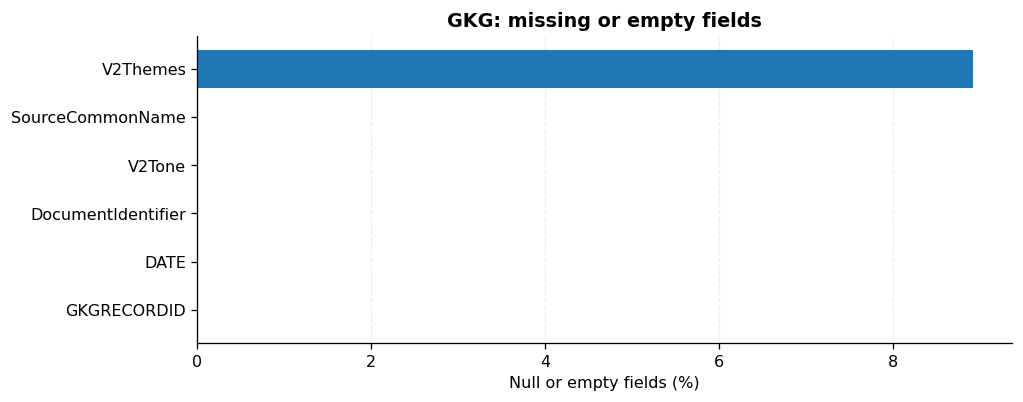

In [ ]:
row_count, gkg_profile = raw_profile(KEEP_COLUMNS)
print('Rows:', f'{row_count:,}')
display(gkg_profile)
plot_missing_profile(gkg_profile, 'GKG: missing or empty fields')

## 3. Timestamp parsing validation

In [ ]:
display(timestamp_validation('DATE', '%Y%m%d%H%M%S'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,parse_failures,min_time,max_time
0,0.0,2026-09-17,2026-10-17 23:45:00


## 4. Validate all seven V2Tone components

`V2Tone` is parsed in the documented order:

1. `tone`
2. `positive`
3. `negative`
4. `polarity`
5. `activity`
6. `self_group`
7. `word_count`

The checks below measure malformed component counts, numeric conversion failures, zeros, observed ranges, and broad sanity-range violations. Nothing is clipped or removed.

In [ ]:
TONE_COMPONENTS = [
    ('tone', 1, -100, 100),
    ('positive', 2, 0, 100),
    ('negative', 3, 0, 100),
    ('polarity', 4, 0, 100),
    ('activity', 5, 0, 100),
    ('self_group', 6, 0, 100),
    ('word_count', 7, 0, None),
]

component_count = con.execute('''
    SELECT
        COUNT(*) AS rows,
        SUM(CASE WHEN NULLIF(TRIM(V2Tone), '') IS NULL THEN 1 ELSE 0 END) AS missing_or_empty_v2tone,
        SUM(CASE WHEN NULLIF(TRIM(V2Tone), '') IS NOT NULL
                  AND 1 + LENGTH(V2Tone) - LENGTH(REPLACE(V2Tone, ',', '')) <> 7
                 THEN 1 ELSE 0 END) AS rows_not_having_7_components
    FROM raw
''').fetchdf()
display(component_count)

rows = []
for name, position, low, high in TONE_COMPONENTS:
    raw_part = f"NULLIF(TRIM(SPLIT_PART(V2Tone, ',', {position})), '')"
    parsed = f"TRY_CAST({raw_part} AS DOUBLE)"
    range_case = '0'
    if high is None:
        range_case = f"SUM(CASE WHEN {parsed} < {low} THEN 1 ELSE 0 END)"
    else:
        range_case = f"SUM(CASE WHEN {parsed} < {low} OR {parsed} > {high} THEN 1 ELSE 0 END)"

    result = con.execute(f'''
        SELECT
            SUM(CASE WHEN {raw_part} IS NOT NULL AND {parsed} IS NULL THEN 1 ELSE 0 END) AS parse_failures,
            SUM(CASE WHEN {parsed} = 0 THEN 1 ELSE 0 END) AS zeros,
            MIN({parsed}) AS min,
            MAX({parsed}) AS max,
            {range_case} AS out_of_range
        FROM raw
        WHERE NULLIF(TRIM(V2Tone), '') IS NOT NULL
    ''').fetchdf().iloc[0]
    rows.append({'component': name, **result.to_dict()})

v2tone_validation = pd.DataFrame(rows)
display(v2tone_validation)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rows,missing_or_empty_v2tone,rows_not_having_7_components
0,8331004,0.0,0.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 5. Unit of analysis, repeated record IDs, and repeated URLs

In [ ]:
content_signature = "MD5(CONCAT_WS('|', " + ', '.join(
    f"COALESCE({q(c)}, '<NULL>')" for c in KEEP_COLUMNS if c != 'GKGRECORDID'
) + "))"

id_summary = con.execute(f'''
    WITH x AS (
        SELECT
            NULLIF(TRIM(GKGRECORDID), '') AS record_id,
            source_file,
            {content_signature} AS content_signature
        FROM raw
        WHERE NULLIF(TRIM(GKGRECORDID), '') IS NOT NULL
    ),
    g AS (
        SELECT
            record_id,
            COUNT(*) AS rows,
            COUNT(DISTINCT source_file) AS files,
            COUNT(DISTINCT content_signature) AS versions
        FROM x
        GROUP BY 1
    )
    SELECT
        COUNT(*) AS distinct_record_ids,
        SUM(CASE WHEN rows > 1 THEN 1 ELSE 0 END) AS repeated_record_ids,
        SUM(CASE WHEN files > 1 THEN 1 ELSE 0 END) AS ids_across_files,
        SUM(CASE WHEN rows > 1 AND versions = 1 THEN 1 ELSE 0 END) AS identical_repeat_groups,
        SUM(CASE WHEN rows > 1 AND versions > 1 THEN 1 ELSE 0 END) AS conflicting_repeat_groups,
        SUM(CASE WHEN rows > 1 THEN rows - 1 ELSE 0 END) AS surplus_rows
    FROM g
''').fetchdf()
display(id_summary)

url_summary = con.execute('''
    WITH g AS (
        SELECT
            NULLIF(TRIM(DocumentIdentifier), '') AS document_id,
            COUNT(*) AS rows,
            COUNT(DISTINCT NULLIF(TRIM(GKGRECORDID), '')) AS record_ids,
            COUNT(DISTINCT source_file) AS files
        FROM raw
        WHERE NULLIF(TRIM(DocumentIdentifier), '') IS NOT NULL
        GROUP BY 1
    )
    SELECT
        COUNT(*) AS distinct_document_ids,
        SUM(CASE WHEN rows > 1 THEN 1 ELSE 0 END) AS repeated_document_ids,
        SUM(CASE WHEN record_ids > 1 THEN 1 ELSE 0 END) AS urls_with_multiple_record_ids,
        SUM(CASE WHEN files > 1 THEN 1 ELSE 0 END) AS urls_across_files,
        MAX(rows) AS max_rows_for_one_document
    FROM g
''').fetchdf()
display(url_summary)

`GKGRECORDID` is treated as the record-level key. Repeated IDs are separated into identical-content and conflicting-content groups before any later deduplication decision. Repeated document URLs are reported as a separate structural property rather than assumed to be errors.

## 6. Time coverage, daily spikes, partial dates, missing dates, and file overlap

In [ ]:
gkg_daily, gkg_file_ranges, gkg_overlaps = time_coverage(
    'DATE', '%Y%m%d%H%M%S', 'GKG: daily record volume'
)

### Focused check: September 17, 2026 at 13:00 UTC

In [ ]:
gap_check = con.execute('''
    SELECT DATE AS gkg_date, COUNT(*) AS row_count
    FROM raw
    WHERE DATE IN ('20260917124500', '20260917130000', '20260917131500')
    GROUP BY 1
''').fetchdf()

expected = pd.DataFrame({
    'gkg_date': ['20260917124500', '20260917130000', '20260917131500']
})
gap_check = expected.merge(gap_check, on='gkg_date', how='left').fillna({'row_count': 0})
gap_check['row_count'] = gap_check['row_count'].astype(int)
display(gap_check)

## 7. Weekday and UTC-hour patterns

In [ ]:
time_patterns = con.execute('''
    WITH x AS (
        SELECT TRY_STRPTIME(NULLIF(TRIM(DATE), ''), '%Y%m%d%H%M%S') AS ts
        FROM raw
    )
    SELECT
        DAYNAME(ts) AS weekday,
        EXTRACT('hour' FROM ts) AS hour_utc,
        COUNT(*) AS records
    FROM x
    WHERE ts IS NOT NULL
    GROUP BY 1, 2
''').fetchdf()

weekday = time_patterns.groupby('weekday', as_index=False)['records'].sum()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday['weekday'] = pd.Categorical(weekday['weekday'], weekday_order, ordered=True)
weekday = weekday.sort_values('weekday')

fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.bar(weekday['weekday'].astype(str), weekday['records'])
ax.set_ylabel('Records')
ax.set_title('GKG records by weekday')
ax.yaxis.set_major_formatter(HUMAN)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

hourly = time_patterns.groupby('hour_utc', as_index=False)['records'].sum()
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(hourly['hour_utc'], hourly['records'], marker='o')
ax.set_xlabel('UTC hour')
ax.set_ylabel('Records')
ax.set_title('GKG records by UTC hour')
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(HUMAN)
plt.tight_layout()
plt.show()

## 8. Sources and translation coverage

In [ ]:
source_counts = con.execute('''
    SELECT SourceCommonName AS source, COUNT(*) AS records
    FROM raw
    WHERE NULLIF(TRIM(SourceCommonName), '') IS NOT NULL
    GROUP BY 1
    ORDER BY records DESC
    LIMIT 20
''').fetchdf()
display(source_counts)

fig, ax = plt.subplots(figsize=(9, 6))
plot_df = source_counts.sort_values('records')
ax.barh(plot_df['source'], plot_df['records'])
ax.set_xlabel('GKG records')
ax.set_title('Top 20 GKG sources')
ax.xaxis.set_major_formatter(HUMAN)
plt.tight_layout()
plt.show()

translation = con.execute('''
    SELECT
        SUM(CASE WHEN REGEXP_MATCHES(GKGRECORDID, '^[0-9]{14}-T') THEN 1 ELSE 0 END) AS translated_records,
        COUNT(*) AS rows
    FROM raw
''').fetchdf()
translation['translated_pct'] = 100 * translation['translated_records'] / translation['rows']
display(translation)

## 9. V2Tone distributions and relationships

In [ ]:
tone_sample = con.execute('''
    SELECT
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 1)), '') AS DOUBLE) AS tone,
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 2)), '') AS DOUBLE) AS positive,
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 3)), '') AS DOUBLE) AS negative,
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 4)), '') AS DOUBLE) AS polarity,
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 5)), '') AS DOUBLE) AS activity,
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 6)), '') AS DOUBLE) AS self_group,
        TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 7)), '') AS DOUBLE) AS word_count
    FROM raw
    WHERE NULLIF(TRIM(V2Tone), '') IS NOT NULL
      AND MOD(HASH(COALESCE(GKGRECORDID, '')), 1000) < 100
    LIMIT 200000
''').fetchdf()

display(tone_sample.describe(percentiles=[.25, .5, .75, .95]).T)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(tone_sample['tone'].dropna(), bins=70)
ax.set_xlabel('Overall tone')
ax.set_ylabel('Sampled records')
ax.set_title('GKG overall tone distribution')
plt.tight_layout()
plt.show()

corr = tone_sample.corr(method='spearman')
display(corr.round(3))

## 10. Themes

In [ ]:
theme_summary = con.execute('''
    WITH x AS (
        SELECT
            CASE
                WHEN NULLIF(TRIM(V2Themes), '') IS NULL THEN 0
                ELSE 1 + LENGTH(V2Themes) - LENGTH(REPLACE(V2Themes, ';', ''))
            END AS n_themes
        FROM raw
    )
    SELECT
        SUM(CASE WHEN n_themes = 0 THEN 1 ELSE 0 END) AS records_with_no_themes,
        MEDIAN(n_themes) AS median_themes,
        QUANTILE_CONT(n_themes, 0.75) AS q3_themes,
        QUANTILE_CONT(n_themes, 0.95) AS p95_themes,
        MAX(n_themes) AS max_themes
    FROM x
''').fetchdf()
display(theme_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,records_with_no_themes,median_themes,q3_themes,p95_themes,max_themes
0,743205.0,30.0,57.0,124.0,4974


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,theme,records
0,CRISISLEX_C07_SAFETY,517566
1,UNGP_FORESTS_RIVERS_OCEANS,511938
2,CRISISLEX_CRISISLEXREC,503896
3,USPEC_POLITICS_GENERAL1,489785
4,LEADER,431583
5,EPU_ECONOMY_HISTORIC,429843
6,GENERAL_GOVERNMENT,413600
7,USPEC_POLICY1,407119
8,MANMADE_DISASTER_IMPLIED,402800
9,WB_696_PUBLIC_SECTOR_MANAGEMENT,395555


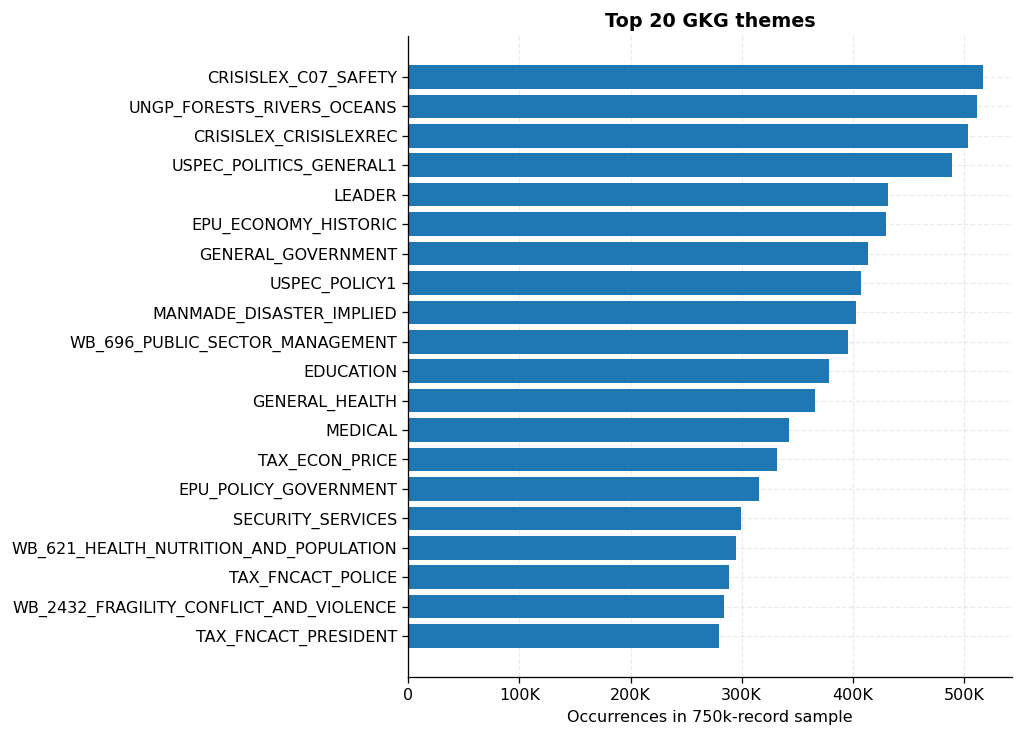

In [ ]:
top_themes = con.execute('''
    WITH sampled AS (
        SELECT V2Themes
        FROM raw
        WHERE NULLIF(TRIM(V2Themes), '') IS NOT NULL
          AND MOD(HASH(COALESCE(GKGRECORDID, '')), 1000) < 100
        LIMIT 750000
    ),
    exploded AS (
        SELECT TRIM(SPLIT_PART(item, ',', 1)) AS theme
        FROM sampled,
             UNNEST(STRING_SPLIT(V2Themes, ';')) AS t(item)
    )
    SELECT theme, COUNT(*) AS records
    FROM exploded
    WHERE theme <> ''
    GROUP BY 1
    ORDER BY records DESC
    LIMIT 20
''').fetchdf()
display(top_themes)

fig, ax = plt.subplots(figsize=(9, 6.5))
plot_df = top_themes.sort_values('records')
ax.barh(plot_df['theme'], plot_df['records'])
ax.set_xlabel('Occurrences in 750k-record sample')
ax.set_title('Top 20 GKG themes')
ax.xaxis.set_major_formatter(HUMAN)
plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,theme,records,mean_tone,median_tone
0,CRISISLEX_C07_SAFETY,517632,-3.273167,-3.278689
1,UNGP_FORESTS_RIVERS_OCEANS,512055,-0.249496,-0.041859
2,CRISISLEX_CRISISLEXREC,503886,-3.577786,-3.526448
3,USPEC_POLITICS_GENERAL1,489761,-0.669983,-0.694444
4,LEADER,431490,-0.945139,-0.945626
5,EPU_ECONOMY_HISTORIC,429835,0.485213,0.613497
6,GENERAL_GOVERNMENT,413576,-1.221989,-1.157296
7,USPEC_POLICY1,407092,-0.818715,-0.769231
8,MANMADE_DISASTER_IMPLIED,402859,-2.378451,-2.197802
9,WB_696_PUBLIC_SECTOR_MANAGEMENT,395570,-1.931861,-1.843318


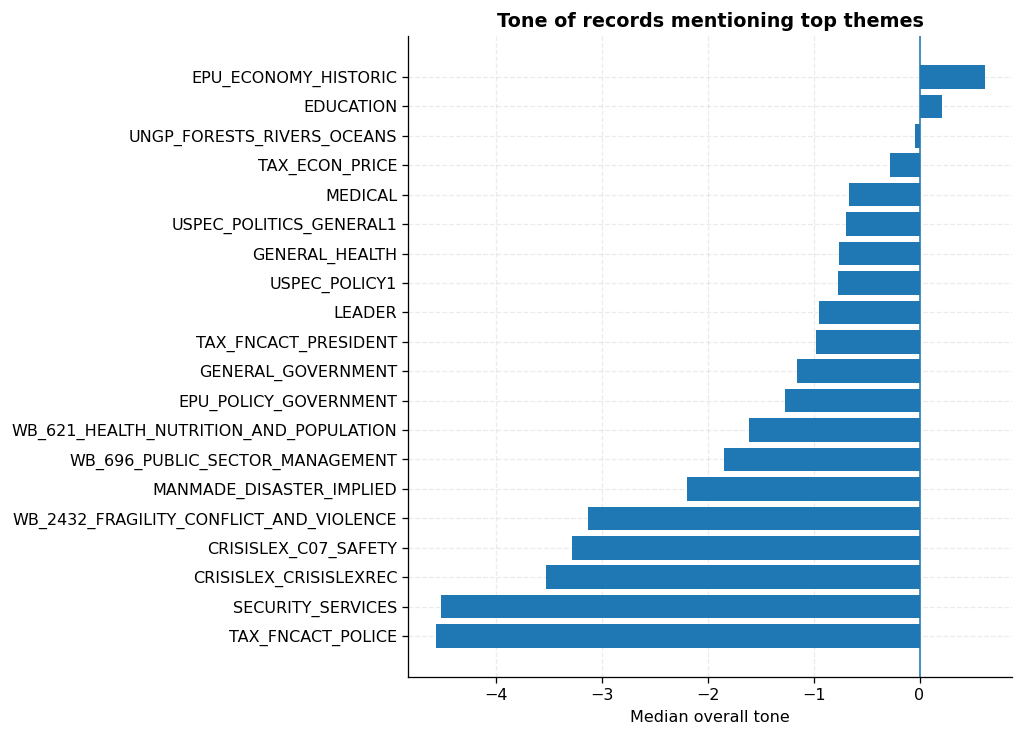

In [ ]:
if len(top_themes):
    theme_list = ', '.join(sql_string(x) for x in top_themes['theme'])
    theme_tone = con.execute(f'''
        WITH sampled AS (
            SELECT V2Themes, V2Tone
            FROM raw
            WHERE NULLIF(TRIM(V2Themes), '') IS NOT NULL
              AND NULLIF(TRIM(V2Tone), '') IS NOT NULL
              AND MOD(HASH(COALESCE(GKGRECORDID, '')), 1000) < 100
            LIMIT 750000
        ),
        exploded AS (
            SELECT
                TRIM(SPLIT_PART(item, ',', 1)) AS theme,
                TRY_CAST(NULLIF(TRIM(SPLIT_PART(V2Tone, ',', 1)), '') AS DOUBLE) AS tone
            FROM sampled,
                 UNNEST(STRING_SPLIT(V2Themes, ';')) AS t(item)
        )
        SELECT theme, COUNT(*) AS records, AVG(tone) AS mean_tone, MEDIAN(tone) AS median_tone
        FROM exploded
        WHERE theme IN ({theme_list}) AND tone IS NOT NULL
        GROUP BY 1
        ORDER BY records DESC
    ''').fetchdf()
    display(theme_tone)

    fig, ax = plt.subplots(figsize=(9, 6.5))
    plot_df = theme_tone.sort_values('median_tone')
    ax.barh(plot_df['theme'], plot_df['median_tone'])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel('Median overall tone')
    ax.set_title('Tone of records mentioning top themes')
    plt.tight_layout()
    plt.show()